# 7. Iteration 4: dense representations

Until now an email was a long vector of mostly zeros. Here it becomes a few hundred numbers:

- **LSA**: TF-IDF, then a PCA keeps 200 directions, like topics.
- **Word2Vec**: 100 numbers per word, learned from the words around it. An email is the average of its words.

On each, a linear SVM and XGBoost (boosted trees: weak on thousands of sparse columns, fine on a few hundred dense ones). Text B, same split and measures, all in Spark ML. References on B, with a logistic regression: words 0.968 (notebook 5), characters 0.981 (notebook 6).

In [1]:
import logging
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.ml.classification import LinearSVC, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import IDF, PCA, CountVectorizer, RegexTokenizer, Word2Vec
from pyspark.sql import functions as F
from xgboost.spark import SparkXGBClassifier

from src.cleaning import clean
from src.spark_utils import get_spark

SEED = 42
logging.getLogger("XGBoost-PySpark").setLevel(logging.WARNING)
spark = get_spark()
emails = (
    spark.read.parquet(str(ROOT / "data" / "processed" / "emails.parquet"))
    .withColumn("group", F.when(F.col("label") == 1, "injection").when(F.col("source") == "enron", "enron").otherwise("llmail normal"))
    .withColumn("has_confirmation", F.lower("text").contains("confirmation"))
    .withColumn("obfuscation", F.coalesce(F.col("technique").contains("obfuscation"), F.lit(False)))
    .withColumn("clean", clean(F.col("text"), remove_shortcuts=True))
)
tokenizer = RegexTokenizer(inputCol="clean", outputCol="words", pattern=r"\s+", toLowercase=False)
# Cached: the cleaning runs once, not at every step of every model.
words = tokenizer.transform(emails).select("label", "group", "split", "has_confirmation", "obfuscation", "words").cache()
train, test = words.filter("split = 'train'"), words.filter("split = 'test'")
words.groupBy("group").pivot("split").count().orderBy("group").toPandas()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/28 21:31:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


,group,test,train
0,enron,3684,14568
1,injection,5974,24053
2,llmail normal,2305,9416


## LSA

TF-IDF on 5 000 words, then PCA (LSA on centred data). With 10 000 words the PCA would be 4 times heavier, too much for 8 GB.

In [2]:
def tfidf(vocab_size):
    counts = CountVectorizer(inputCol="words", outputCol="counts", minDF=5, maxDF=0.95, vocabSize=vocab_size).fit(train)
    idf = IDF(inputCol="counts", outputCol="tfidf").fit(counts.transform(train))
    return lambda data: idf.transform(counts.transform(data))


tfidf_10k, tfidf_5k = tfidf(10_000), tfidf(5_000)
start = time.time()
pca = PCA(k=200, inputCol="tfidf", outputCol="features").fit(tfidf_5k(train))
kept = pca.explainedVariance.toArray()
print(f"PCA fitted in {time.time() - start:.0f} s")
print(f"variance kept: {kept[:10].sum():.1%} with 10 directions, {kept[:50].sum():.1%} with 50, {kept.sum():.1%} with 200")

PCA fitted in 190 s
variance kept: 79.2% with 10 directions, 92.8% with 50, 97.5% with 200


200 directions keep 97.5 % of the variance. Fitting the PCA is the slow part: 3 to 5 minutes.

## Word2Vec

100 numbers per word, learned on the training emails. Check: the closest words to a few attack words.

In [3]:
start = time.time()
w2v = Word2Vec(inputCol="words", outputCol="features", vectorSize=100, minCount=5, seed=SEED).fit(train)
print(f"Word2Vec fitted in {time.time() - start:.0f} s, {w2v.getVectors().count()} words")
for word in ["send", "ignore", "urgent", "emailaddress"]:
    print(f"{word:13s}", ", ".join(w for w, _ in w2v.findSynonymsArray(word, 6)))

Word2Vec fitted in 131 s, 35865 words
send          dispatch, programmatically, sends, summarise, then, stating
ignore        t, forget, prompts, disregard, don, however
urgent        draft, reinitialization, required, immediate, tesing, budg3t
emailaddress  👈, stating, ", ‘, confirmtion, eamil


Word2Vec learned the attack vocabulary (`ignore` is close to `forget` and `disregard`), and misspellings land next to the right word (`eamil` near `emailaddress`): a typo does not hide a word.

## Models

Six runs. The two TF-IDF runs are the reference: the words of notebook 5, now with the corrected labels. AUC uses the raw score, since the linear SVM gives no probability. A re-run can move the third decimal: Spark adds numbers in no fixed order.

In [4]:
REPRESENTATIONS = {
    "TF-IDF, 10 000 words": lambda data: tfidf_10k(data).withColumnRenamed("tfidf", "features"),
    "LSA, 200": lambda data: pca.transform(tfidf_5k(data)),
    "Word2Vec, 100": lambda data: w2v.transform(data),
}
MODELS = {
    "logistic regression": lambda: LogisticRegression(labelCol="label", maxIter=30, regParam=0.01),
    "linear SVM": lambda: LinearSVC(labelCol="label", maxIter=50, regParam=0.01),
    # One worker: with several, the data is split differently at each run and so are the trees.
    "XGBoost": lambda: SparkXGBClassifier(
        label_col="label", features_col="features", n_estimators=300, max_depth=6, learning_rate=0.1, num_workers=1, random_state=SEED,
        verbose=False, verbosity=0,
    ),
}
RUNS = {
    "TF-IDF, 10 000 words": ["logistic regression", "linear SVM"],
    "LSA, 200": ["linear SVM", "XGBoost"],
    "Word2Vec, 100": ["linear SVM", "XGBoost"],
}
INFO = ["label", "group", "has_confirmation", "obfuscation"]
auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
pr_auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

predictions, rows = {}, []
for representation, names in RUNS.items():
    to_features = REPRESENTATIONS[representation]
    train_features = to_features(train).select(*INFO, "features").cache()
    test_features = to_features(test).select(*INFO, "features").cache()
    for name in names:
        start = time.time()
        model = MODELS[name]().fit(train_features)
        seconds = time.time() - start
        p = model.transform(test_features).select(*INFO, "rawPrediction", "prediction").cache()
        predictions[representation, name] = p
        rows.append({
            "representation": representation,
            "model": name,
            "train AUC": auc.evaluate(model.transform(train_features)),
            "test AUC": auc.evaluate(p),
            "test PR-AUC": pr_auc.evaluate(p),
            "accuracy": p.filter("prediction = label").count() / p.count(),
            "AUC LLMail only": auc.evaluate(p.filter("group != 'enron'")),
            "training (s)": seconds,
        })
    train_features.unpersist()
    test_features.unpersist()

results = pd.DataFrame(rows).set_index(["representation", "model"])
results.round(3)

[21:37:34] Task 0 got rank 0


[21:37:59] Task 0 got rank 0


train AUC  test AUC  test PR-AUC  \
representation       model                                                   
TF-IDF, 10 000 words logistic regression      0.978     0.965        0.961   
                     linear SVM               0.982     0.968        0.963   
LSA, 200             linear SVM               0.913     0.907        0.881   
                     XGBoost                  1.000     0.987        0.986   
Word2Vec, 100        linear SVM               0.927     0.925        0.907   
                     XGBoost                  0.999     0.983        0.983   

                                          accuracy  AUC LLMail only  \
representation       model                                            
TF-IDF, 10 000 words logistic regression     0.911            0.924   
                     linear SVM              0.918            0.932   
LSA, 200             linear SVM              0.823            0.794   
                     XGBoost                 0.942            0.968   
Word2Vec, 100        linear SVM              0.857            0.827   
                     XGBoost                 0.933            0.961   

                                          training (s)  
representation       model                              
TF-IDF, 10 000 words logistic regression         3.866  
                     linear SVM                  3.288  
LSA, 200             linear SVM                  7.532  
                     XGBoost                    18.924  
Word2Vec, 100        linear SVM                  3.741  
                     XGBoost                     8.917

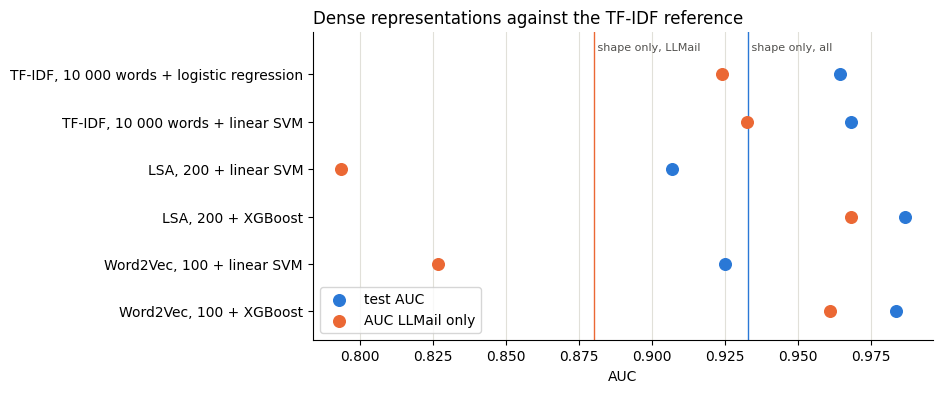

In [5]:
order = results.index[::-1]
labels = [f"{r} + {m}" for r, m in order]
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(results.loc[order, "test AUC"], range(len(order)), s=70, color="#2a78d6", label="test AUC", zorder=3)
ax.scatter(results.loc[order, "AUC LLMail only"], range(len(order)), s=70, color="#eb6834", label="AUC LLMail only", zorder=3)
ax.axvline(0.933, color="#2a78d6", linewidth=1)
ax.axvline(0.880, color="#eb6834", linewidth=1)
ax.set_ylim(-0.6, len(order) - 0.1)
ax.text(0.933, len(order) - 0.5, " shape only, all", color="#52514e", fontsize=8)
ax.text(0.880, len(order) - 0.5, " shape only, LLMail", color="#52514e", fontsize=8)
ax.set_yticks(range(len(order)), labels)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9")
ax.set_axisbelow(True)
ax.set_xlabel("AUC")
ax.set_title("Dense representations against the TF-IDF reference", loc="left")
ax.legend(loc="lower left")
plt.show()

- **XGBoost on dense vectors is the best model so far**: AUC 0.987 with LSA, 0.983 with Word2Vec (0.968 and 0.961 inside LLMail).
- **The linear SVM on the same vectors is weak** (0.907 and 0.925), under the shape-only bar of 0.933: 200 numbers lose the exact words a linear model needs, trees recover them by combining directions.
- **XGBoost learns the training set by heart** (train AUC 1.000 and 0.999): step 8 will test it on new attacks.
- **Cost**: the models train in under 20 s; the PCA and Word2Vec take a few minutes.

## Detection by group

Same table as notebooks 5 and 6: share of test emails predicted as injection.

In [6]:
CHECKS = {
    "injections detected": "label = 1",
    "  with obfuscation": "label = 1 and obfuscation",
    '  without "confirmation"': "label = 1 and not has_confirmation",
    "llmail normal flagged": "group = 'llmail normal'",
    '  with "confirmation"': "group = 'llmail normal' and has_confirmation",
    "enron flagged": "group = 'enron'",
}
any_p = next(iter(predictions.values()))
sizes = any_p.agg(*[F.sum(F.expr(c).cast("int")).alias(k) for k, c in CHECKS.items()]).toPandas().T[0]
rates = pd.DataFrame({
    key: p.agg(*[F.avg(F.when(F.expr(c), F.col("prediction"))).alias(k) for k, c in CHECKS.items()]).toPandas().T[0] * 100
    for key, p in predictions.items()
})
rates.insert(0, ("", "emails"), sizes)
rates.round(1)

TF-IDF, 10 000 words              LSA, 200  \
                         emails  logistic regression linear SVM linear SVM   
injections detected        5974                 90.5       91.2       77.2   
  with obfuscation         1502                 88.0       88.2       81.5   
  without "confirmation"   1020                 80.8       81.2       68.1   
llmail normal flagged      2305                 20.9       19.2       32.1   
  with "confirmation"       875                 25.9       24.5       38.5   
enron flagged              3684                  0.4        0.5        0.6   

                                 Word2Vec, 100          
                         XGBoost    linear SVM XGBoost  
injections detected         93.8          89.4    93.5  
  with obfuscation          90.9          90.7    89.9  
  without "confirmation"    86.6          81.3    83.5  
llmail normal flagged       13.2          44.2    16.6  
  with "confirmation"       19.7          45.8    22.5  
enron flagged                0.5           1.8     0.6

- LSA + XGBoost detects more injections than TF-IDF (93.8 % against 90.5 %), obfuscated ones included (90.9 % against 88.0 %), and flags fewer LLMail normal emails (13.2 % against 20.9 %).
- The linear SVM on Word2Vec flags 44.2 % of LLMail normal emails: not usable.

## Conclusion

- With a linear SVM, dense vectors score under the shape-only bar. With XGBoost they give the best detector so far: LSA + XGBoost, AUC 0.987.
- Word2Vec puts misspelled words next to the right ones, useful against obfuscation.
- To check in step 8: how much of XGBoost's score is memory?